# Выявление мошеннических транзакций средствами Spark ML

**Задание 1 · Воспроизводимый эксперимент · Credit Card Fraud Detection**

Цель — построить сохраняемый конвейер, сравнить три семейства классификаторов и проверить перенос
модели на более поздние транзакции. Основная метрика ранжирования — PR-AUC; рабочий порог
выбирается по F1 на отдельном временном validation. Последний период не участвует в выборе решений.

Структура: среда → качество данных → временное разбиение → EDA → Pipeline и CrossValidator →
выбор модели и порогов → контролируемое сравнение со sklearn → независимый тест → сохранение и выводы.

Стенд преподавателя запускает Spark в локальном многопоточном режиме внутри одного контейнера.
Вычисления используют разделённые на партиции DataFrame и Spark ML; многомашинный кластер здесь не заявляется.
Демонстрационный ноутбук по оттоку клиентов сохранён отдельно.


In [1]:
import os
import sys
import json
import math
import time
import hashlib
import platform
import subprocess
import importlib.metadata
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F, types as T, Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, SQLTransformer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler as SkScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, auc

SEED = 42
PROFILE = os.environ.get('FRAUD_PROFILE', 'full')
assert PROFILE in {'full', 'smoke'}
WORK = next((p for p in [Path.cwd(), Path.cwd() / 'work'] if (p / 'data' / 'creditcard.csv').exists()), None)
if WORK is None:
    raise FileNotFoundError('Поместите исходный creditcard.csv в папку work/data и запустите ноутбук из work.')
OUT = WORK / 'artifacts' / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
for folder in ['figures', 'tables', 'models', 'predictions']:
    (OUT / folder).mkdir(exist_ok=True)
NUMERIC = [f'V{i}' for i in range(1, 29)] + ['Amount']
RAW_FEATURES = ['Time'] + NUMERIC
RUN_STARTED = datetime.now(timezone.utc).isoformat()
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)

def json_value(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (np.ndarray, pd.Index)):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)

def save_json(name, value):
    destination = OUT / name
    temporary = destination.with_suffix(destination.suffix + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=json_value, allow_nan=False), encoding='utf-8')
    temporary.replace(destination)

def table(name, frame, columns=None):
    frame.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
    visible = frame if columns is None else frame[columns]
    display(visible.style.format(precision=4, na_rep='—').hide(axis='index'))

def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

spark = (SparkSession.builder.appName('CreditCardFraudDetection')
         .master(f'local[{min(6, os.cpu_count() or 1)}]')
         .config('spark.sql.shuffle.partitions', '12')
         .config('spark.default.parallelism', '12')
         .config('spark.sql.session.timeZone', 'UTC')
         .config('spark.sql.adaptive.enabled', 'true')
         .config('spark.ui.showConsoleProgress', 'false')
         .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
versions = {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient']}
versions['pyspark'] = spark.version
environment = {'python': sys.version, 'platform': platform.platform(), 'packages': versions,
               'master': spark.sparkContext.master, 'driver_memory': spark.sparkContext.getConf().get('spark.driver.memory'),
               'profile': PROFILE, 'seed': SEED, 'started_utc': RUN_STARTED}
save_json('environment.json', environment)
display(environment)
if PROFILE == 'smoke':
    display(Markdown('**Технический smoke-запуск: уменьшенные данные и сетки. Его оценки не являются итоговыми результатами.**'))
assert spark.version.startswith('3.5.'), spark.version


{'python': '3.11.10 | packaged by conda-forge | (main, Oct 16 2024, 01:27:36) [GCC 13.3.0]',
 'platform': 'Linux-6.18.40.1-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'packages': {'numpy': '1.26.4',
  'pandas': '2.0.3',
  'scikit-learn': '1.5.2',
  'matplotlib': '3.9.2',
  'nbformat': '5.10.4',
  'nbclient': '0.10.0',
  'pyspark': '3.5.3'},
 'master': 'local[6]',
 'driver_memory': '4g',
 'profile': 'full',
 'seed': 42,
 'started_utc': '2026-10-12T00:43:23.509579+00:00'}

## 1. Источник и качество данных

[Исходный набор MLG-ULB на Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
содержит 284 807 операций, из них 492 мошеннические. `V1–V28` уже являются анонимизированными
PCA-компонентами. `Time` означает число секунд от первой операции, а не час суток.
Точность сверяется с исходным файлом, а не с переобработанными или сбалансированными копиями.

Пропуски числовых признаков допускаются интерфейсом Pipeline и заполняются обученными медианами.
Бесконечности, отрицательные суммы и неправильные метки считаются ошибками данных.


In [2]:
source_path = WORK / 'data' / 'creditcard.csv'
with source_path.open('rb') as stream:
    source_hash = hashlib.file_digest(stream, 'sha256').hexdigest()
schema = T.StructType([T.StructField(name, T.DoubleType(), True) for name in ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount']] + [T.StructField('Class', T.IntegerType(), True)])
raw = (spark.read.option('header', True).option('mode', 'FAILFAST').option('enforceSchema', False)
       .schema(schema).csv(str(source_path)).persist(StorageLevel.MEMORY_AND_DISK))
quality = raw.agg(F.count('*').alias('rows'), F.sum('Class').alias('frauds'),
                  F.sum(F.when(F.col('Class').isNull() | ~F.col('Class').isin(0, 1), 1).otherwise(0)).alias('bad_labels'),
                  F.sum(F.when(F.col('Time').isNull() | F.isnan('Time') | (F.col('Time') < 0), 1).otherwise(0)).alias('bad_time'),
                  F.sum(F.when(F.col('Amount') < 0, 1).otherwise(0)).alias('negative_amount')).first().asDict()
assert quality['rows'] == 284807 and quality['frauds'] == 492, f'Неожиданная версия данных: {quality}'
assert quality['bad_labels'] == quality['bad_time'] == quality['negative_amount'] == 0, quality
missing = raw.agg(*[F.sum(F.when(F.col(c).isNull() | F.isnan(c), 1).otherwise(0)).alias(c) for c in RAW_FEATURES]).toPandas().T.reset_index()
missing.columns = ['feature', 'missing_count']
infinite = raw.agg(*[F.sum(F.when(F.abs(F.col(c)) == float('inf'), 1).otherwise(0)).alias(c) for c in RAW_FEATURES]).first().asDict()
assert sum(infinite.values()) == 0, infinite
data = raw.withColumn('group_id', F.sha2(F.to_json(F.struct(*[F.col(c) for c in RAW_FEATURES])), 256)).persist(StorageLevel.MEMORY_AND_DISK)
groups = data.groupBy('group_id').agg(F.count('*').alias('multiplicity'), F.countDistinct('Class').alias('label_count'))
duplicate_summary = groups.agg(F.sum(F.col('multiplicity') - 1).alias('repeated_rows'),
                               F.sum(F.when(F.col('multiplicity') > 1, 1).otherwise(0)).alias('repeated_groups'),
                               F.sum(F.when(F.col('label_count') > 1, 1).otherwise(0)).alias('conflicting_groups')).first().asDict()
source_info = {'url': 'https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud', 'sha256': source_hash,
               'bytes': source_path.stat().st_size, **quality, **duplicate_summary}
save_json('source.json', source_info)
table('data_quality', pd.DataFrame({'Показатель': list(source_info), 'Значение': [str(value) for value in source_info.values()]}))
table('missing_values', missing)
raw.printSchema()
data.select('Time', 'Amount', 'Class', 'V1', 'V2').show(5)
raw.unpersist()


Показатель,Значение
url,https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
sha256,76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
bytes,150828752
rows,284807
frauds,492
bad_labels,0
bad_time,0
negative_amount,0
repeated_rows,1081
repeated_groups,773


feature,missing_count
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


root
 |-- Time: double (nullable = true)
 |-- V1: double (nullable = true)
 |-- V2: double (nullable = true)
 |-- V3: double (nullable = true)
 |-- V4: double (nullable = true)
 |-- V5: double (nullable = true)
 |-- V6: double (nullable = true)
 |-- V7: double (nullable = true)
 |-- V8: double (nullable = true)
 |-- V9: double (nullable = true)
 |-- V10: double (nullable = true)
 |-- V11: double (nullable = true)
 |-- V12: double (nullable = true)
 |-- V13: double (nullable = true)
 |-- V14: double (nullable = true)
 |-- V15: double (nullable = true)
 |-- V16: double (nullable = true)
 |-- V17: double (nullable = true)
 |-- V18: double (nullable = true)
 |-- V19: double (nullable = true)
 |-- V20: double (nullable = true)
 |-- V21: double (nullable = true)
 |-- V22: double (nullable = true)
 |-- V23: double (nullable = true)
 |-- V24: double (nullable = true)
 |-- V25: double (nullable = true)
 |-- V26: double (nullable = true)
 |-- V27: double (nullable = true)
 |-- V28: double (nulla

+----+------+-----+------------------+-------------------+
|Time|Amount|Class|                V1|                 V2|
+----+------+-----+------------------+-------------------+
| 0.0|149.62|    0|  -1.3598071336738|-0.0727811733098497|
| 0.0|  2.69|    0|  1.19185711131486|   0.26615071205963|
| 1.0|378.66|    0| -1.35835406159823|  -1.34016307473609|
| 1.0| 123.5|    0|-0.966271711572087| -0.185226008082898|
| 2.0| 69.99|    0| -1.15823309349523|  0.877736754848451|
+----+------+-----+------------------+-------------------+
only showing top 5 rows



DataFrame[Time: double, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9: double, V10: double, V11: double, V12: double, V13: double, V14: double, V15: double, V16: double, V17: double, V18: double, V19: double, V20: double, V21: double, V22: double, V23: double, V24: double, V25: double, V26: double, V27: double, V28: double, Amount: double, Class: int]

## 2. Временное разбиение и независимость эксперимента

Ранние 60% операций предназначены для обучения, следующие 20% — для выбора семейства модели
и порога, последние 20% — для единственной итоговой оценки. Границы проходят между различными
значениями `Time`; поэтому одинаковые транзакции не оказываются по разные стороны границы.
Дубликаты сохраняются: без идентификатора операции нельзя доказать, что они являются ошибкой выгрузки.

На всём наборе проверяется только целостность данных. Связи признаков с целевой переменной далее
исследуются на train. Модель, порог и преобразования не адаптируются к test.


In [3]:
cut_train, cut_valid = data.approxQuantile('Time', [0.6, 0.8], 0.0)
assert cut_train < cut_valid
split_frames = {
    'train': data.filter(F.col('Time') <= cut_train),
    'validation': data.filter((F.col('Time') > cut_train) & (F.col('Time') <= cut_valid)),
    'test': data.filter(F.col('Time') > cut_valid),
}
if PROFILE == 'smoke':
    split_frames = {name: frame.filter(F.col('Class') == 1).unionByName(
        frame.filter(F.col('Class') == 0).orderBy('group_id').limit(6000)) for name, frame in split_frames.items()}
split_frames = {name: frame.repartition(12, 'group_id').persist(StorageLevel.MEMORY_AND_DISK) for name, frame in split_frames.items()}
split_rows = []
for name, frame in split_frames.items():
    row = frame.agg(F.count('*').alias('rows'), F.sum('Class').alias('frauds'),
                    F.min('Time').alias('min_time'), F.max('Time').alias('max_time'),
                    F.countDistinct('group_id').alias('groups')).first().asDict()
    assert 0 < row['frauds'] < row['rows']
    split_rows.append({'split': name, **row, 'fraud_rate': row['frauds'] / row['rows']})
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert split_frames[left].select('group_id').join(split_frames[right].select('group_id'), 'group_id', 'inner').limit(1).count() == 0
split_summary = pd.DataFrame(split_rows)
assert split_rows[0]['max_time'] < split_rows[1]['min_time'] <= split_rows[1]['max_time'] < split_rows[2]['min_time']
if PROFILE == 'full':
    assert split_summary['rows'].sum() == quality['rows']
train, validation, test = [split_frames[name] for name in ['train', 'validation', 'test']]
table('splits', split_summary)
save_json('splits.json', {'train_cutoff': cut_train, 'validation_cutoff': cut_valid, 'parts': split_rows})
data.unpersist()


split,rows,frauds,min_time,max_time,groups,fraud_rate
train,170888,360,0.0000,120396.0000,170248,0.0021
validation,56958,57,120397.0000,145248.0000,56758,0.0010
test,56961,75,145249.0000,172792.0000,56720,0.0013


DataFrame[Time: double, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9: double, V10: double, V11: double, V12: double, V13: double, V14: double, V15: double, V16: double, V17: double, V18: double, V19: double, V20: double, V21: double, V22: double, V23: double, V24: double, V25: double, V26: double, V27: double, V28: double, Amount: double, Class: int, group_id: string]

## 3. Разведочный анализ обучающего периода

При редком положительном классе высокая accuracy достижима без обнаружения мошенничества.
Распределения показываются раздельно по классам и с нормировкой внутри класса, чтобы большинство
не скрывало меньшинство. Для суммы используется логарифмическое преобразование без удаления крупных операций.
Выводы о значении PCA-компонент ограничены их статистическими свойствами.


В train доля мошенничества **0.211%**. Прогноз «всегда 0» даёт accuracy **99.789%**, но recall и F1 равны нулю.

Class,count
0,170528
1,360


summary,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
count,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888,170888
mean,-0.16985071432228968,0.04076414166102586,0.49302937570745375,0.11741810157014879,-0.17608407786911956,0.05822957230937659,-0.08066357115282477,0.03221127859015703,0.018868334295504687,-0.029848912467872177,0.19290977820717356,-0.0975576114202696,0.06494416095792437,0.08216063452247802,0.1330988947330068,-0.007665610527472962,0.041921821204670646,-0.050923082918381005,-0.019292909459754596,0.030939705269399966,-0.028275826045012248,-0.08374289766734845,-0.022461143308051098,0.009005465658653032,0.09226911435372803,0.012610085647868124,0.002096603368884378,0.0024427565806416553,87.33627650858895
stddev,1.8505217324705774,1.6108576795730127,1.3832474019632768,1.3718957332248318,1.3386059343216608,1.2951290992317526,1.2085160765995115,1.2276208090288547,1.1522838484042222,1.0968601349814096,1.0471247996858521,1.1430173184426358,1.048394243941017,0.9783087298833824,0.9505367913187561,0.8829954663631603,0.9129569903268112,0.8349210818521348,0.8126378774939594,0.7258285819448334,0.743718968256571,0.6673194766183388,0.5845081533539808,0.5987534082421904,0.4655089168046409,0.490666323465431,0.391950810401894,0.3073156320483857,245.95095952323672
min,-56.407509631329,-72.7157275629303,-33.6809840183525,-5.51969712328415,-42.1478983728015,-26.1605059358433,-43.5572415712451,-73.2167184552674,-13.4340663182301,-24.5882624372475,-4.04989491435061,-18.6837146333443,-5.79188120632084,-19.2143254902614,-4.49894467676621,-14.1298545174931,-25.1627993693248,-9.49874592104677,-7.21352743017759,-22.8385483047643,-34.8303821448146,-10.933143697655,-44.8077352037913,-2.83662691870341,-10.2953970749851,-2.60455055280817,-22.5656793207827,-11.7108956394515,0.0
25%,-0.986895849343493,-0.53920213819524,-0.0647931211331156,-0.743690515156205,-0.828944042019243,-0.691195211243664,-0.586388180510233,-0.162688342406848,-0.660329824820265,-0.519289986154403,-0.565511000594625,-0.509684562917415,-0.626979328208493,-0.336921676767231,-0.44989575018394,-0.471303330330512,-0.417760212175218,-0.524221832304139,-0.497681830188977,-0.183601541507584,-0.230719053194145,-0.546893880315684,-0.170347362877934,-0.332479571279755,-0.19596566259755,-0.330385705102239,-0.0651638271065893,-0.0270795720206603,5.48
50%,-0.184059806467359,0.109414586227644,0.623231577848751,0.124059640810453,-0.226462609575955,-0.202759877736148,-0.0319985855998927,0.0566066833938258,-0.079157391896781,-0.111554640255624,0.119575018834366,0.110670015621873,0.0318636635386549,0.0929328244672243,0.243991755167443,0.0637403275614795,-0.0181520959084114,-0.0524516261623847,-0.0224832985744279,-0.0362107308852761,-0.054478757198875,-0.0669484892673995,-0.0362679816605736,0.0593783197827353,0.13559887585047,-0.0590444551238284,0.00868445160723901,0.021145839968541,21.87
75%,1.18437848855702,0.80383895861123,1.29711790747965,0.937445118945907,0.374106647403836,0.448899026017064,0.462492408367357,0.350823023670147,0.640981089810529,0.408177045058076,0.998902404330503,0.617312584907867,0.743014525684231,0.52789816431019,0.827993848629566,0.527701011091546,0.435381333199586,0.43197365414361,0.467335568043105,0.155679453019706,0.128280041773282,0.362983125775499,0.0986803848841479,0.41576566946908,0.399404239013719,0.272873168560222,0.0896412614715659,0.078260012614978,76.68
max,2.43920748106102,22.0577289904909,9.38255843282114,16.8753440335975,34.8016658766686,22.5292984665587,36.6772679454031,20.0072083651213,15.5949946071278,23.7451361206545,12.0189131816199,7.8483920756446,4.56900895856606,10.5267660517847,5.78451388962946,6.0985294505409,9.25352625047285,5.04106918541184,5.2283417900513,39.4209042482199,27.2028391573154,10.5030900899454,19.0029418232927,4.02286589044732,7

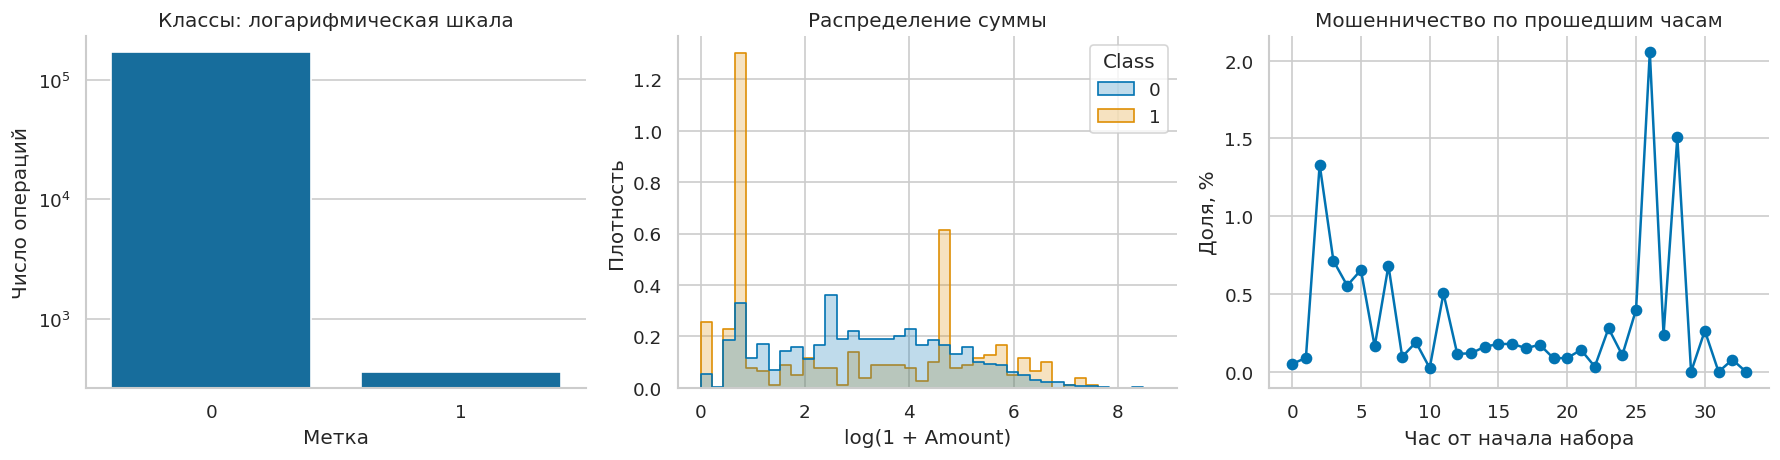

feature,mean_difference_in_train_std
V17,-9.0065
V14,-7.5383
V12,-6.2615
V3,-6.1359
V10,-6.0180
V7,-5.7517
V16,-5.5940
V11,3.9676
V4,3.4856
V18,-3.4191


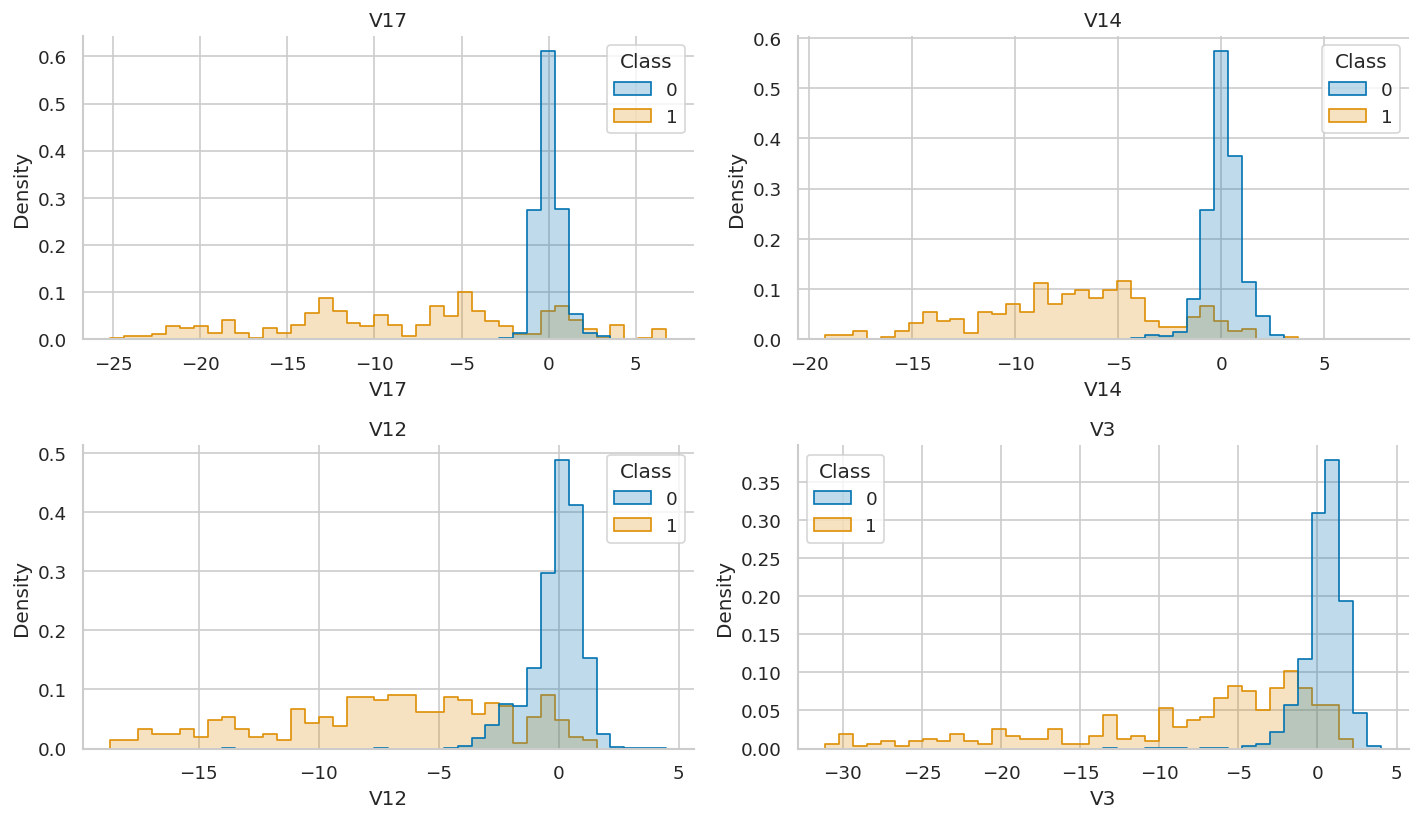

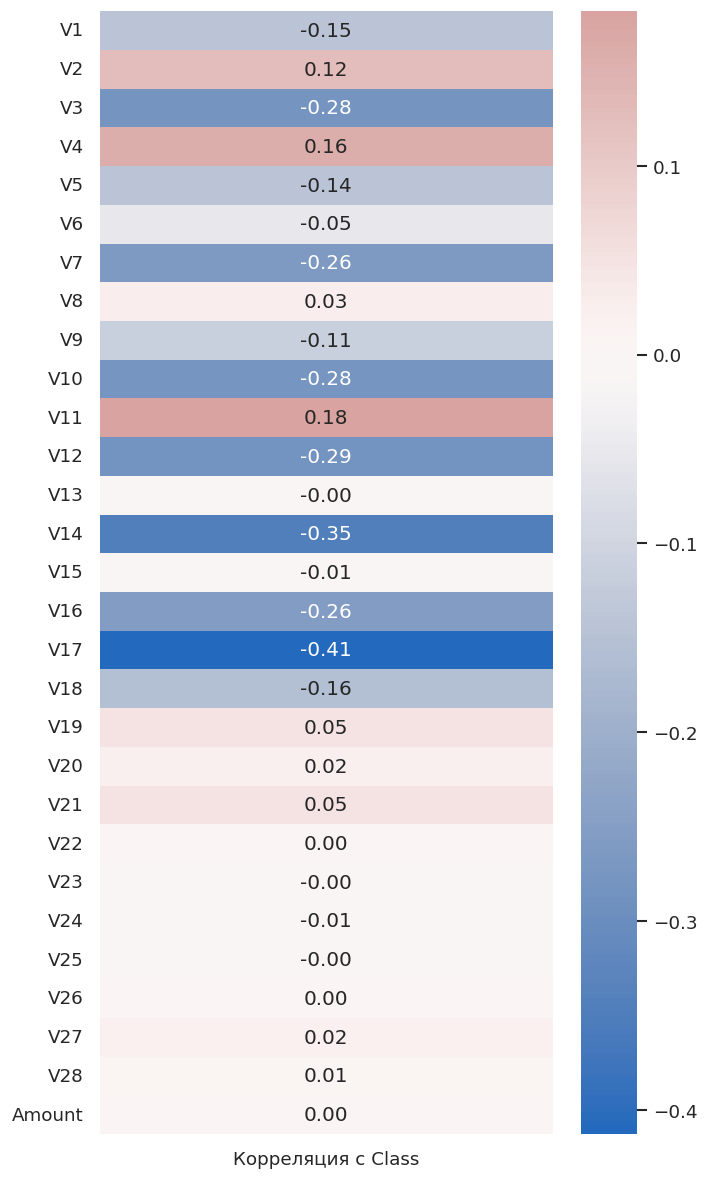

Наибольшие стандартизированные различия средних в train: **V17, V14, V12, V3**. Это описательный анализ, а не причинное объяснение. Все 28 PCA-компонент остаются в модели; отбор по результатам тестового периода не выполняется.

In [4]:
train_counts = train.groupBy('Class').count().orderBy('Class').toPandas()
train_prevalence = split_rows[0]['fraud_rate']
display(Markdown(f'В train доля мошенничества **{train_prevalence:.3%}**. Прогноз «всегда 0» даёт accuracy **{1 - train_prevalence:.3%}**, но recall и F1 равны нулю.'))
table('train_class_counts', train_counts)
summary = train.select(*NUMERIC).summary('count', 'mean', 'stddev', 'min', '25%', '50%', '75%', 'max').toPandas()
table('train_statistics', summary)
eda = train.filter(F.col('Class') == 1).unionByName(train.filter(F.col('Class') == 0).orderBy('group_id').limit(5000)).select('Time', 'Class', *NUMERIC).toPandas()
assert len(eda) <= 6000
eda['log_amount'] = np.log1p(eda['Amount'])
hourly = train.groupBy(F.floor(F.col('Time') / 3600).alias('elapsed_hour')).agg(F.count('*').alias('transactions'), F.sum('Class').alias('frauds')).orderBy('elapsed_hour').toPandas()
hourly['fraud_rate'] = hourly['frauds'] / hourly['transactions']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=train_counts, x='Class', y='count', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set(title='Классы: логарифмическая шкала', xlabel='Метка', ylabel='Число операций')
sns.histplot(data=eda, x='log_amount', hue='Class', stat='density', common_norm=False, bins=40, element='step', ax=axes[1])
axes[1].set(title='Распределение суммы', xlabel='log(1 + Amount)', ylabel='Плотность')
axes[2].plot(hourly['elapsed_hour'], hourly['fraud_rate'] * 100, marker='o')
axes[2].set(title='Мошенничество по прошедшим часам', xlabel='Час от начала набора', ylabel='Доля, %')
figure('eda_overview')
class_moments = train.groupBy('Class').agg(*[F.avg(c).alias(c) for c in NUMERIC]).orderBy('Class').toPandas().set_index('Class')
std_row = train.agg(*[F.stddev(c).alias(c) for c in NUMERIC]).first().asDict()
effect = ((class_moments.loc[1] - class_moments.loc[0]) / pd.Series(std_row)).sort_values(key=abs, ascending=False)
table('standardized_mean_differences', effect.rename('mean_difference_in_train_std').rename_axis('feature').reset_index())
top_features = list(effect.head(4).index)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, name in zip(axes.flat, top_features):
    sns.histplot(data=eda, x=name, hue='Class', stat='density', common_norm=False, bins=40, element='step', ax=ax)
    ax.set_title(name)
figure('eda_feature_distributions')
correlations = train.agg(*[F.corr(c, 'Class').alias(c) for c in NUMERIC]).toPandas().T
correlations.columns = ['Корреляция с Class']
plt.figure(figsize=(6, 10))
sns.heatmap(correlations, center=0, cmap='vlag', annot=True, fmt='.2f')
figure('eda_target_correlations')
display(Markdown(f'Наибольшие стандартизированные различия средних в train: **{", ".join(top_features)}**. '
                 'Это описательный анализ, а не причинное объяснение. Все 28 PCA-компонент остаются в модели; '
                 'отбор по результатам тестового периода не выполняется.'))
del eda


## 4. Общая архитектура Pipeline

Обучаемые медианы находятся внутри Pipeline. Затем SQLTransformer вычисляет `log1p(Amount)`,
VectorAssembler собирает 29 признаков. Для LR применяется StandardScaler; деревья используют
немасштабированные признаки. Служебные поля, `Time`, метка и веса не входят в вектор.

Веса положительного класса 1 и 10 — заранее заданные гипотезы поиска. Они применяются только
к обучению; метрики считаются без весов на естественном распределении классов. Взвешенный
классификатор возвращает оценку риска, которую нельзя автоматически считать калиброванной вероятностью.


In [5]:
FILLED = [f'{name}_filled' for name in NUMERIC]
MODEL_FEATURES = [f'V{i}_filled' for i in range(1, 29)] + ['log_amount']
assert len(MODEL_FEATURES) == 29 and not set(MODEL_FEATURES) & {'Class', 'Time', 'group_id', 'fold', 'weight_10'}

def make_pipeline(kind):
    stages = [Imputer(strategy='median', inputCols=NUMERIC, outputCols=FILLED),
              SQLTransformer(statement='SELECT *, LOG(1.0 + Amount_filled) AS log_amount FROM __THIS__'),
              VectorAssembler(inputCols=MODEL_FEATURES, outputCol='assembled', handleInvalid='error')]
    if kind == 'lr':
        stages.append(StandardScaler(inputCol='assembled', outputCol='features', withMean=True, withStd=True))
        estimator = LogisticRegression(featuresCol='features', labelCol='Class', maxIter=200, tol=1e-6, standardization=False)
    elif kind == 'rf':
        estimator = RandomForestClassifier(featuresCol='assembled', labelCol='Class', seed=SEED, maxBins=32)
    elif kind == 'gbt':
        estimator = GBTClassifier(featuresCol='assembled', labelCol='Class', seed=SEED, maxBins=32, stepSize=0.1)
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages + [estimator]), estimator

group_folds = train.groupBy('group_id').agg(F.max('Class').alias('stratum'))
fold_order = Window.partitionBy('stratum').orderBy(F.sha2(F.concat(F.col('group_id'), F.lit(str(SEED))), 256))
group_folds = group_folds.withColumn('fold', F.pmod(F.row_number().over(fold_order) - 1, F.lit(3)).cast('int')).select('group_id', 'fold')
train_cv = (train.join(group_folds, 'group_id').withColumn('weight_10', F.when(F.col('Class') == 1, 10.0).otherwise(1.0))
            .persist(StorageLevel.MEMORY_AND_DISK))
fold_summary = train_cv.groupBy('fold').agg(F.count('*').alias('rows'), F.sum('Class').alias('frauds')).orderBy('fold').toPandas()
assert len(fold_summary) == 3 and (fold_summary['frauds'] > 0).all()
assert train_cv.groupBy('group_id').agg(F.countDistinct('fold').alias('n')).filter('n > 1').count() == 0
table('cv_folds', fold_summary)
evaluator = BinaryClassificationEvaluator(labelCol='Class', rawPredictionCol='probability', metricName='areaUnderPR', numBins=0)

def grid_for(kind, estimator):
    grid = ParamGridBuilder()
    if PROFILE == 'smoke':
        if kind == 'lr':
            grid.addGrid(estimator.regParam, [0.01]).addGrid(estimator.elasticNetParam, [0.0])
        elif kind == 'rf':
            grid.addGrid(estimator.numTrees, [5]).addGrid(estimator.maxDepth, [3])
        else:
            grid.addGrid(estimator.maxIter, [5]).addGrid(estimator.maxDepth, [2])
        return grid.addGrid(estimator.weightCol, ['']).build()
    if kind == 'lr':
        grid.addGrid(estimator.regParam, [0.001, 0.01, 0.1]).addGrid(estimator.elasticNetParam, [0.0, 0.5])
    elif kind == 'rf':
        grid.addGrid(estimator.numTrees, [100, 200]).addGrid(estimator.maxDepth, [5, 10])
    else:
        grid.addGrid(estimator.maxIter, [40, 80]).addGrid(estimator.maxDepth, [3, 5])
    return grid.addGrid(estimator.weightCol, ['', 'weight_10']).build()


fold,rows,frauds
0,56970,125
1,56971,119
2,56947,116


## 5. Подбор гиперпараметров

Для каждого семейства CrossValidator переобучает **весь Pipeline** в трёх фолдах раннего периода.
Группы дубликатов не разделяются между фолдами. Внутренняя кросс-валидация не является
скользящей временной проверкой: перенос на будущее оценивается отдельными validation и test.

Критерий подбора — Spark `areaUnderPR` без сокращения числа точек кривой (`numBins=0`).
В полном режиме: 28 конфигураций, 84 обучения по фолдам и три финальных переобучения на train.
Параллельность поиска равна 1; каждое обучение использует доступные Spark-потоки.
Завершённые семейства сохраняются вместе со всеми оценками CV. При повторном запуске они
восстанавливаются только при совпадении исходного кода, файла данных, профиля и версий библиотек.
В таблицах сохраняется исходное время обучения; повторная загрузка не считается новым обучением.


In [6]:
models = {}
search_rows = []
fit_times = {}
best_parameters = {}
notebook_document = json.loads((WORK / 'fraud_detection.ipynb').read_text(encoding='utf-8'))
code_sources = [''.join(cell['source']) for cell in notebook_document['cells'] if cell['cell_type'] == 'code']
checkpoint_key = hashlib.sha256(json.dumps({'code': code_sources, 'data': source_hash,
    'profile': PROFILE, 'versions': versions, 'seed': SEED}, sort_keys=True).encode()).hexdigest()
for kind in ['lr', 'rf', 'gbt']:
    checkpoint_path = OUT / f'{kind}_cv_checkpoint.json'
    checkpoint = json.loads(checkpoint_path.read_text(encoding='utf-8')) if checkpoint_path.exists() else None
    if checkpoint and checkpoint['key'] == checkpoint_key:
        models[kind] = PipelineModel.load(str(OUT / 'models' / f'{kind}_before_threshold'))
        search_rows.extend(checkpoint['rows'])
        fit_times[kind] = checkpoint['seconds']
        best_parameters[kind] = checkpoint['best_parameters']
        print(f'{kind}: восстановлено из контрольной точки; PR-AUC CV={max(row["mean_cv_pr_auc"] for row in checkpoint["rows"]):.5f}', flush=True)
        continue
    if checkpoint_path.exists():
        checkpoint_path.unlink()
    pipeline, estimator = make_pipeline(kind)
    parameter_grid = grid_for(kind, estimator)
    print(f'{datetime.now().isoformat(timespec="seconds")} | {kind}: {len(parameter_grid)} конфигураций × 3 фолда', flush=True)
    started = time.perf_counter()
    cv = CrossValidator(estimator=pipeline, estimatorParamMaps=parameter_grid, evaluator=evaluator,
                        numFolds=3, foldCol='fold', seed=SEED, parallelism=1, collectSubModels=False)
    fitted = cv.fit(train_cv)
    fit_times[kind] = time.perf_counter() - started
    models[kind] = fitted.bestModel
    if kind == 'lr':
        logistic_summary = models[kind].stages[-1].summary
        assert np.isfinite(logistic_summary.objectiveHistory).all()
        assert logistic_summary.totalIterations < 200, 'LR не достигла сходимости за 200 итераций'
    for index, parameters in enumerate(parameter_grid):
        search_rows.append({'model': kind, 'candidate': index,
                            'mean_cv_pr_auc': float(fitted.avgMetrics[index]),
                            'std_cv_pr_auc': float(fitted.stdMetrics[index]),
                            'parameters': json.dumps({p.name: value for p, value in parameters.items()}, sort_keys=True)})
    best_index = int(np.argmax(fitted.avgMetrics))
    best_parameters[kind] = {p.name: value for p, value in parameter_grid[best_index].items()}
    models[kind].write().overwrite().save(str(OUT / 'models' / f'{kind}_before_threshold'))
    save_json(f'{kind}_cv_checkpoint.json', {'key': checkpoint_key,
        'rows': [row for row in search_rows if row['model'] == kind], 'seconds': fit_times[kind],
        'best_parameters': best_parameters[kind], 'completed_utc': datetime.now(timezone.utc).isoformat()})
    save_json('search_progress.json', {'completed': list(models), 'seconds': fit_times, 'best_parameters': best_parameters})
    print(f'{kind}: PR-AUC CV={fitted.avgMetrics[best_index]:.5f}; {fit_times[kind] / 60:.1f} мин', flush=True)
    del fitted
search_table = pd.DataFrame(search_rows)
table('cross_validation', search_table.sort_values(['model', 'mean_cv_pr_auc'], ascending=[True, False]))
save_json('best_parameters.json', best_parameters)
train_cv.unpersist()


2026-10-12T00:44:11 | lr: 12 конфигураций × 3 фолда


lr: PR-AUC CV=0.77481; 3.2 мин


2026-10-12T00:47:25 | rf: 8 конфигураций × 3 фолда


rf: PR-AUC CV=0.87816; 6.8 мин


2026-10-12T00:54:17 | gbt: 8 конфигураций × 3 фолда


gbt: PR-AUC CV=0.84326; 9.8 мин


model,candidate,mean_cv_pr_auc,std_cv_pr_auc,parameters
gbt,6,0.8433,0.0550,"{""maxDepth"": 5, ""maxIter"": 80, ""weightCol"": """"}"
gbt,2,0.8404,0.0490,"{""maxDepth"": 5, ""maxIter"": 40, ""weightCol"": """"}"
gbt,4,0.8325,0.0478,"{""maxDepth"": 3, ""maxIter"": 80, ""weightCol"": """"}"
gbt,0,0.8220,0.0429,"{""maxDepth"": 3, ""maxIter"": 40, ""weightCol"": """"}"
gbt,3,0.8140,0.0458,"{""maxDepth"": 5, ""maxIter"": 40, ""weightCol"": ""weight_10""}"
gbt,7,0.8116,0.0447,"{""maxDepth"": 5, ""maxIter"": 80, ""weightCol"": ""weight_10""}"
gbt,5,0.7978,0.0689,"{""maxDepth"": 3, ""maxIter"": 80, ""weightCol"": ""weight_10""}"
gbt,1,0.7820,0.0569,"{""maxDepth"": 3, ""maxIter"": 40, ""weightCol"": ""weight_10""}"
lr,1,0.7748,0.0459,"{""elasticNetParam"": 0.0, ""regParam"": 0.001, ""weightCol"": ""weight_10""}"
lr,0,0.7703,0.0431,"{""elasticNetParam"": 0.0, ""regParam"": 0.001, ""weightCol"": """"}"


DataFrame[group_id: string, Time: double, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9: double, V10: double, V11: double, V12: double, V13: double, V14: double, V15: double, V16: double, V17: double, V18: double, V19: double, V20: double, V21: double, V22: double, V23: double, V24: double, V25: double, V26: double, V27: double, V28: double, Amount: double, Class: int, fold: int, weight_10: double]

## 6. Выбор семейства и рабочего порога на validation

Основная метрика ранжирования — PR-AUC. Рабочий порог максимизирует F1, то есть гармоническое
среднее precision и recall для мошеннического класса. Стоимость ошибок банком не задана;
выбор F1 является явным учебным допущением, а не оптимизацией денежного ущерба.

Порог ищется между соседними различными оценками риска. При равном F1 выбирается более высокий
precision, затем более высокий порог. Семейство выбирается по validation PR-AUC, затем по F1,
затем по простоте LR → RF → GBT. После этого решение замораживается.


model,spark_pr_auc,average_precision,threshold,precision,recall,f1,search_seconds
lr,0.7153,0.7163,0.6636,0.7213,0.7719,0.7458,193.1974
rf,0.7665,0.7669,0.3503,0.9318,0.7193,0.8119,410.4192
gbt,0.6191,0.6287,0.4652,0.7917,0.6667,0.7238,586.2193


Зафиксирована модель **RF**, порог **0.35026400**. Тестовые оценки пока не вычислялись.

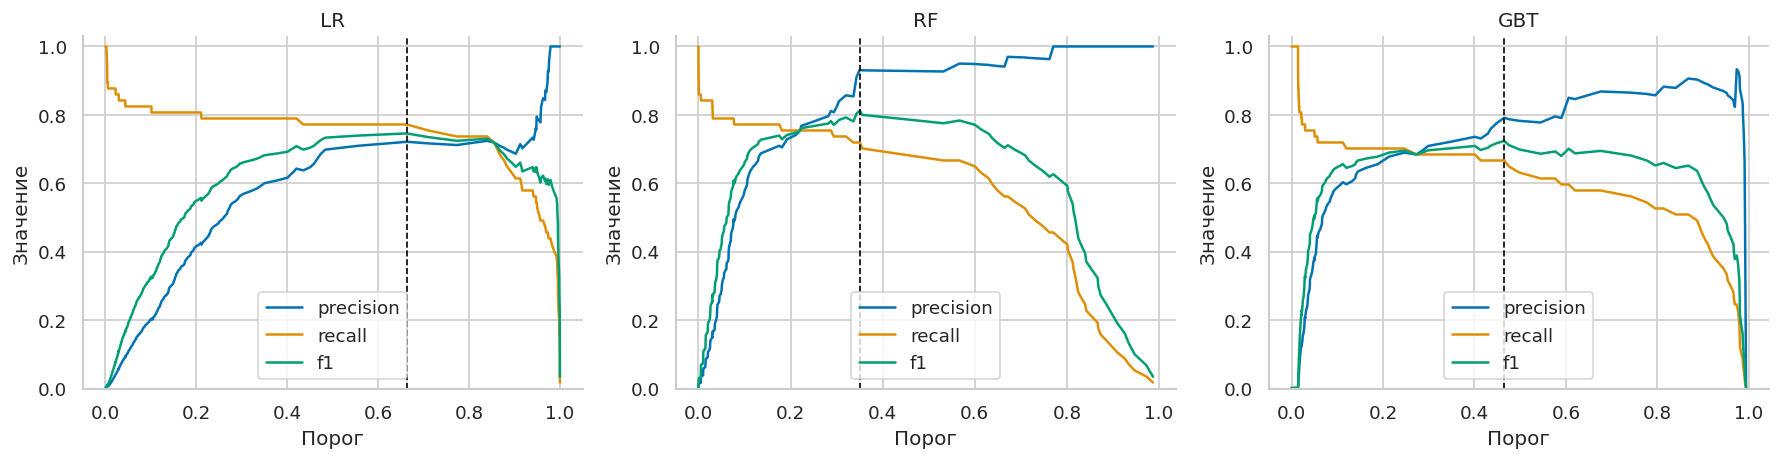

In [7]:
def bounded_scores(predictions, maximum=100000):
    count = predictions.count()
    assert count <= maximum, f'Превышен предел локальной оценки: {count}'
    result = predictions.select('group_id', 'Time', 'Amount', 'Class', vector_to_array('probability')[1].alias('score')).toPandas()
    assert len(result) == count and np.isfinite(result['score']).all()
    assert result['score'].between(0, 1).all()
    return result

def threshold_metrics(y, scores, threshold):
    y = np.asarray(y, dtype=int)
    positive = np.asarray(scores) > threshold
    tp = int(np.sum(positive & (y == 1)))
    fp = int(np.sum(positive & (y == 0)))
    fn = int(np.sum(~positive & (y == 1)))
    tn = int(np.sum(~positive & (y == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    return {'threshold': float(threshold), 'precision': precision, 'recall': recall, 'f1': f1,
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn, 'accuracy': (tp + tn) / len(y),
            'false_alerts_per_10000': fp / len(y) * 10000}

def ranking_metrics(y, scores):
    precision, recall, _ = precision_recall_curve(y, scores)
    return {'pr_auc_common': float(auc(recall, precision)),
            'average_precision': float(average_precision_score(y, scores)),
            'roc_auc': float(roc_auc_score(y, scores))}

def choose_threshold(scores):
    grouped = scores.groupby('score')['Class'].agg(['sum', 'count']).sort_index(ascending=False)
    values = grouped.index.to_numpy(dtype=float)
    if len(values) < 2:
        raise ValueError('Модель возвращает постоянную оценку риска; невозможно подобрать рабочий порог.')
    tp = grouped['sum'].cumsum().to_numpy()[:-1]
    fp = grouped['count'].cumsum().to_numpy()[:-1] - tp
    fn = int(scores['Class'].sum()) - tp
    thresholds = values[:-1] / 2 + values[1:] / 2
    thresholds = np.where(thresholds >= values[:-1], values[1:], thresholds)
    result = pd.DataFrame({'threshold': thresholds, 'precision': tp / (tp + fp),
                           'recall': tp / (tp + fn), 'f1': 2 * tp / (2 * tp + fp + fn)})
    edge = pd.DataFrame([threshold_metrics(scores['Class'], scores['score'], 0.0)])[result.columns]
    result = pd.concat([result, edge], ignore_index=True)
    selected = result.sort_values(['f1', 'precision', 'threshold'], ascending=False, kind='stable').iloc[0]
    return float(selected['threshold']), result

def apply_threshold(model, threshold):
    classifier = model.stages[-1]
    if classifier.__class__.__name__ == 'LogisticRegressionModel':
        classifier.setThreshold(threshold)
    else:
        classifier.setThresholds([1.0 - threshold, threshold])
    return model

validation_scores = {}
validation_rows = []
thresholds = {}
threshold_curves = {}
for kind, model in models.items():
    prediction = model.transform(validation).persist(StorageLevel.MEMORY_AND_DISK)
    validation_scores[kind] = bounded_scores(prediction)
    native_auc = evaluator.evaluate(prediction)
    threshold, curve = choose_threshold(validation_scores[kind])
    thresholds[kind] = threshold
    threshold_curves[kind] = curve
    apply_threshold(model, threshold)
    values = validation_scores[kind]
    validation_rows.append({'model': kind, 'spark_pr_auc': native_auc,
                            **ranking_metrics(values['Class'], values['score']),
                            **threshold_metrics(values['Class'], values['score'], threshold),
                            'search_seconds': fit_times[kind]})
    prediction.unpersist()
    curve.to_csv(OUT / 'tables' / f'{kind}_threshold_curve.csv', index=False)
validation_table = pd.DataFrame(validation_rows)
selection = validation_table.assign(complexity=validation_table['model'].map({'lr': 0, 'rf': 1, 'gbt': 2}))
winner = selection.sort_values(['spark_pr_auc', 'f1', 'complexity'], ascending=[False, False, True], kind='stable').iloc[0]['model']
table('validation_models', validation_table, ['model', 'spark_pr_auc', 'average_precision', 'threshold', 'precision', 'recall', 'f1', 'search_seconds'])
save_json('selection.json', {'winner': winner, 'thresholds': thresholds, 'selection_data': 'validation', 'test_used': False})
display(Markdown(f'Зафиксирована модель **{winner.upper()}**, порог **{thresholds[winner]:.8f}**. Тестовые оценки пока не вычислялись.'))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kind in zip(axes, ['lr', 'rf', 'gbt']):
    curve = threshold_curves[kind].sort_values('threshold')
    for metric in ['precision', 'recall', 'f1']:
        ax.plot(curve['threshold'], curve[metric], label=metric)
    ax.axvline(thresholds[kind], color='black', linestyle='--', linewidth=1)
    ax.set(title=kind.upper(), xlabel='Порог', ylabel='Значение', ylim=(0, 1.03))
    ax.legend()
figure('validation_thresholds')


## 7. Контролируемое сравнение Spark и sklearn

Чтобы отделить особенности библиотеки от размера данных и семейства модели, отдельно обучаются две
логистические регрессии на **одних и тех же строках train**. Validation и test также общие.
Группы дубликатов сохраняются; подвыборка содержит не более 100 000 строк и примерно сохраняет долю классов.

Обе реализации используют median imputation, log1p суммы, масштабирование и L2-регуляризацию без весов.
Для Spark заранее задан `regParam=0.01`; в sklearn используется `C=1/(n·regParam)`.
Это согласует коэффициент штрафа в усреднённой функции потерь. Численное тождество не требуется:
различаются оптимизаторы, критерии остановки и соглашения о дисперсии StandardScaler.

Время преобразования данных, обучения и материализованного предсказания учитывается отдельно.
Локальные замеры не доказывают преимущество одной библиотеки на многомашинном кластере.


In [8]:
cap = 100000 if PROFILE == 'full' else 6000
sample_groups = train.groupBy('group_id').agg(F.count('*').alias('size'), F.max('Class').alias('stratum'))
stratum_sizes = {r['Class']: r['count'] for r in train.groupBy('Class').count().collect()}
total_train = sum(stratum_sizes.values())
sample_window = Window.partitionBy('stratum').orderBy(F.sha2(F.concat(F.col('group_id'), F.lit('benchmark42')), 256)).rowsBetween(Window.unboundedPreceding, Window.currentRow)
sample_groups = sample_groups.withColumn('cumulative_rows', F.sum('size').over(sample_window))
negative_cap = int(cap * stratum_sizes.get(0, 0) / total_train)
positive_cap = cap - negative_cap
sample_groups = sample_groups.filter(F.col('cumulative_rows') <= F.when(F.col('stratum') == 1, positive_cap).otherwise(negative_cap))
benchmark_train = train.join(sample_groups.select('group_id'), 'group_id').persist(StorageLevel.MEMORY_AND_DISK)
benchmark_n = benchmark_train.count()
assert 0 < benchmark_n <= cap
assert benchmark_train.select('Class').distinct().count() == 2
started = time.perf_counter()
benchmark_pandas = benchmark_train.select('group_id', 'Class', *NUMERIC).orderBy('group_id', 'Class').toPandas()
benchmark_validation = validation.select('group_id', 'Time', 'Amount', 'Class', *[f'V{i}' for i in range(1, 29)]).orderBy('group_id', 'Class').toPandas()
conversion_seconds = time.perf_counter() - started
assert len(benchmark_pandas) == benchmark_n and len(benchmark_validation) <= 100000

def log_amount_array(array):
    result = np.array(array, dtype=float, copy=True)
    result[:, -1] = np.log1p(result[:, -1])
    return result

benchmark_spark, benchmark_estimator = make_pipeline('lr')
benchmark_estimator.setRegParam(0.01).setElasticNetParam(0.0)
started = time.perf_counter()
benchmark_spark_model = benchmark_spark.fit(benchmark_train)
benchmark_spark_fit = time.perf_counter() - started
benchmark_sk = SkPipeline([('imputer', SimpleImputer(strategy='median')),
                           ('amount', FunctionTransformer(log_amount_array, validate=False)),
                           ('scaler', SkScaler()),
                           ('classifier', SkLogisticRegression(C=1 / (benchmark_n * 0.01), solver='lbfgs', max_iter=200, tol=1e-6, random_state=SEED))])
started = time.perf_counter()
benchmark_sk.fit(benchmark_pandas[NUMERIC], benchmark_pandas['Class'])
benchmark_sk_fit = time.perf_counter() - started
assert int(benchmark_sk.named_steps['classifier'].n_iter_.max()) < 200, 'sklearn не достиг сходимости за 200 итераций'
benchmark_spark_validation = bounded_scores(benchmark_spark_model.transform(validation))
benchmark_sk_validation = benchmark_validation[['group_id', 'Time', 'Amount', 'Class']].copy()
benchmark_sk_validation['score'] = benchmark_sk.predict_proba(benchmark_validation[NUMERIC])[:, 1]
benchmark_spark_threshold, _ = choose_threshold(benchmark_spark_validation)
benchmark_sk_threshold, _ = choose_threshold(benchmark_sk_validation)
apply_threshold(benchmark_spark_model, benchmark_spark_threshold)
benchmark_config = {'rows': benchmark_n, 'positive_rows': int(benchmark_pandas['Class'].sum()),
                    'spark_reg_param': 0.01, 'sklearn_C': 1 / (benchmark_n * 0.01),
                    'spark_threshold': benchmark_spark_threshold, 'sklearn_threshold': benchmark_sk_threshold,
                    'conversion_seconds_train_validation': conversion_seconds,
                    'spark_fit_seconds': benchmark_spark_fit, 'sklearn_fit_seconds': benchmark_sk_fit,
                    'pandas_train_bytes': int(benchmark_pandas.memory_usage(deep=True).sum())}
save_json('benchmark_configuration.json', benchmark_config)
table('benchmark_training', pd.DataFrame([benchmark_config]))
save_json('frozen_experiment.json', {'winner': winner, 'thresholds': thresholds, 'parameters': best_parameters,
                                   'benchmark': benchmark_config, 'frozen_utc': datetime.now(timezone.utc).isoformat(),
                                   'test_used_for_selection': False})
del benchmark_pandas, benchmark_validation
benchmark_train.unpersist()


rows,positive_rows,spark_reg_param,sklearn_C,spark_threshold,sklearn_threshold,conversion_seconds_train_validation,spark_fit_seconds,sklearn_fit_seconds,pandas_train_bytes
100000,211,0.0100,0.0010,0.0222,0.0223,2.6169,4.4794,1.9364,35700132


DataFrame[group_id: string, Time: double, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9: double, V10: double, V11: double, V12: double, V13: double, V14: double, V15: double, V16: double, V17: double, V18: double, V19: double, V20: double, V21: double, V22: double, V23: double, V24: double, V25: double, V26: double, V27: double, V28: double, Amount: double, Class: int]

## 8. Независимая оценка на последнем временном периоде

Все решения зафиксированы. Ниже test используется для отчётности и разбора ошибок; по его результатам
не меняются признаки, гиперпараметры или пороги.

PR-AUC отражает компромисс precision–recall при изменении порога, ROC-AUC показывает качество ранжирования
относительно отрицательного класса, а F1 характеризует выбранную рабочую точку. При редком мошенничестве
дополнительно важны абсолютное число пропусков и нагрузка ложных тревог на проверяющих.

**AP и PR-AUC различаются:** average precision использует ступенчатое суммирование, а трапецеидальная
площадь интерполирует точки. Поэтому в таблицах отдельно приведены Spark PR-AUC, общая трапецеидальная
PR-AUC и AP. Сопоставление Spark/sklearn выполняется одной функцией метрик.


model,operating_point,average_precision,pr_auc_common,roc_auc,precision,recall,f1,fp,fn
lr,default_0.5,0.7578,0.7572,0.9842,0.6914,0.7467,0.7179,25,19
lr,validation_f1,0.7578,0.7572,0.9842,0.7941,0.7200,0.7552,14,21
rf,default_0.5,0.7962,0.7959,0.9785,0.9815,0.7067,0.8217,1,22
rf,validation_f1,0.7962,0.7959,0.9785,0.8710,0.7200,0.7883,8,21
gbt,default_0.5,0.7282,0.7268,0.9531,0.8929,0.6667,0.7634,6,25
gbt,validation_f1,0.7282,0.7268,0.9531,0.8793,0.6800,0.7669,7,24


threshold,precision,recall,f1,tp,fp,fn,tn,accuracy,false_alerts_per_10000,average_precision
0.5000,0.0000,0.0000,0.0000,0,0,75,56886,0.9987,0.0000,0.0013


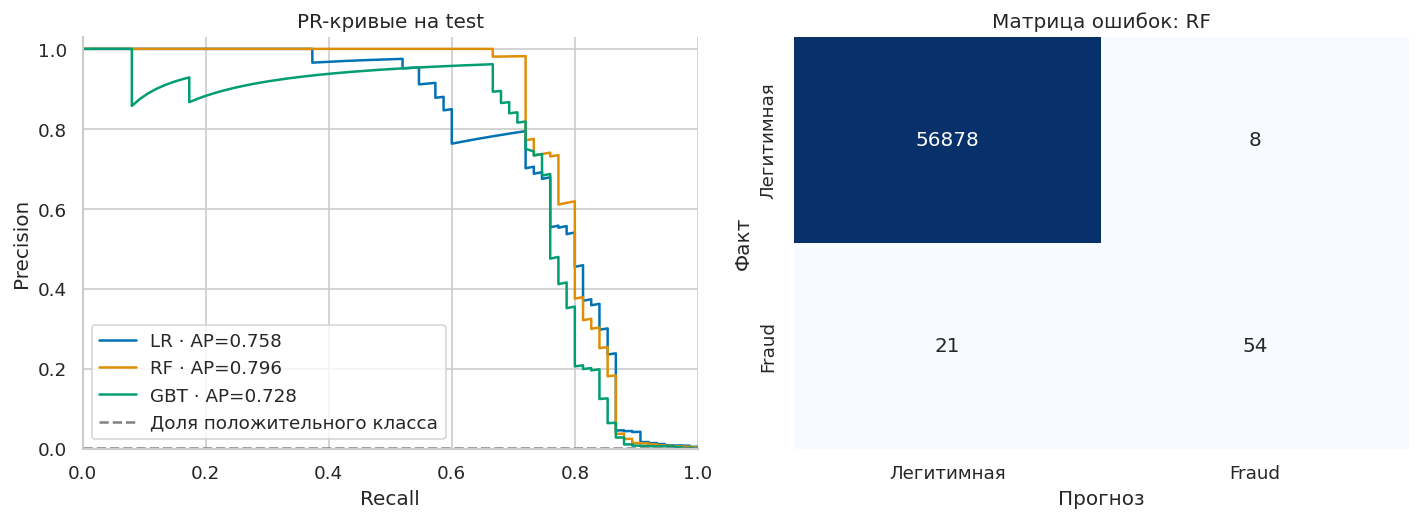

In [9]:
test_scores = {}
test_rows = []
score_times = {}
for kind, model in models.items():
    started = time.perf_counter()
    prediction = model.transform(test).persist(StorageLevel.MEMORY_AND_DISK)
    prediction.select(F.sum(vector_to_array('probability')[1])).collect()
    score_times[kind] = time.perf_counter() - started
    scores = bounded_scores(prediction)
    test_scores[kind] = scores
    native_auc = evaluator.evaluate(prediction)
    native_check = prediction.select(vector_to_array('probability')[1].alias('score'), 'prediction')
    assert native_check.filter(F.col('prediction') != (F.col('score') > F.lit(thresholds[kind])).cast('double')).count() == 0
    ranking = ranking_metrics(scores['Class'], scores['score'])
    for mode, threshold in [('default_0.5', 0.5), ('validation_f1', thresholds[kind])]:
        row = {'model': kind, 'operating_point': mode, 'spark_pr_auc': native_auc, **ranking,
               **threshold_metrics(scores['Class'], scores['score'], threshold),
               'search_seconds': fit_times[kind], 'scoring_seconds': score_times[kind]}
        assert row['tp'] + row['fp'] + row['fn'] + row['tn'] == len(scores)
        test_rows.append(row)
    scores.to_parquet(OUT / 'predictions' / f'{kind}_test.parquet', index=False)
    prediction.unpersist()
test_table = pd.DataFrame(test_rows)
table('test_models', test_table, ['model', 'operating_point', 'average_precision', 'pr_auc_common', 'roc_auc', 'precision', 'recall', 'f1', 'fp', 'fn'])
baseline = threshold_metrics(test_scores[winner]['Class'], np.zeros(len(test_scores[winner])), 0.5)
baseline['average_precision'] = float(test_scores[winner]['Class'].mean())
table('constant_baseline', pd.DataFrame([baseline]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for kind, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(scores['Class'], scores['score'])
    axes[0].plot(recall, precision, label=f'{kind.upper()} · AP={average_precision_score(scores["Class"], scores["score"]):.3f}')
axes[0].axhline(test_scores[winner]['Class'].mean(), linestyle='--', color='grey', label='Доля положительного класса')
axes[0].set(xlabel='Recall', ylabel='Precision', title='PR-кривые на test', xlim=(0, 1), ylim=(0, 1.03))
axes[0].legend()
winner_row = test_table.query('model == @winner and operating_point == "validation_f1"').iloc[0]
matrix = np.array([[winner_row['tn'], winner_row['fp']], [winner_row['fn'], winner_row['tp']]], dtype=int)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1], xticklabels=['Легитимная', 'Fraud'], yticklabels=['Легитимная', 'Fraud'])
axes[1].set(xlabel='Прогноз', ylabel='Факт', title=f'Матрица ошибок: {winner.upper()}')
figure('test_pr_and_confusion')


In [10]:
started = time.perf_counter()
benchmark_test = test.select('group_id', 'Time', 'Amount', 'Class', *[f'V{i}' for i in range(1, 29)]).orderBy('group_id', 'Class').toPandas()
test_conversion_seconds = time.perf_counter() - started
assert len(benchmark_test) <= 100000
spark_benchmark_scores = bounded_scores(benchmark_spark_model.transform(test))
sk_benchmark_scores = benchmark_test[['group_id', 'Time', 'Amount', 'Class']].copy()
sk_benchmark_scores['score'] = benchmark_sk.predict_proba(benchmark_test[NUMERIC])[:, 1]
assert len(spark_benchmark_scores) == len(sk_benchmark_scores)
assert spark_benchmark_scores.groupby(['group_id', 'Class']).size().equals(sk_benchmark_scores.groupby(['group_id', 'Class']).size())
timing_rows = []
for repetition in range(3):
    started = time.perf_counter()
    checksum = benchmark_spark_model.transform(test).select(F.sum(vector_to_array('probability')[1])).first()[0]
    timing_rows.append({'framework': 'spark', 'repetition': repetition, 'seconds': time.perf_counter() - started, 'score_sum': checksum})
    started = time.perf_counter()
    checksum = float(benchmark_sk.predict_proba(benchmark_test[NUMERIC])[:, 1].sum())
    timing_rows.append({'framework': 'sklearn', 'repetition': repetition, 'seconds': time.perf_counter() - started, 'score_sum': checksum})
timings = pd.DataFrame(timing_rows)
benchmark_rows = []
for framework, scores, threshold, fit_seconds in [
    ('spark', spark_benchmark_scores, benchmark_spark_threshold, benchmark_spark_fit),
    ('sklearn', sk_benchmark_scores, benchmark_sk_threshold, benchmark_sk_fit),
]:
    benchmark_rows.append({'framework': framework, 'training_rows': benchmark_n,
                           **ranking_metrics(scores['Class'], scores['score']),
                           **threshold_metrics(scores['Class'], scores['score'], threshold),
                           'fit_seconds': fit_seconds,
                           'median_scoring_seconds': float(timings.loc[timings.framework == framework, 'seconds'].median())})
benchmark_results = pd.DataFrame(benchmark_rows)
table('spark_sklearn_comparison', benchmark_results, ['framework', 'training_rows', 'average_precision', 'precision', 'recall', 'f1', 'fit_seconds', 'median_scoring_seconds'])
table('benchmark_scoring_repetitions', timings)
save_json('benchmark_transfer.json', {'test_to_pandas_seconds': test_conversion_seconds,
                                     'test_dataframe_bytes': int(benchmark_test.memory_usage(deep=True).sum())})
del benchmark_test


framework,training_rows,average_precision,precision,recall,f1,fit_seconds,median_scoring_seconds
spark,100000,0.7997,0.9623,0.6800,0.7969,4.4794,0.3277
sklearn,100000,0.7997,0.9623,0.6800,0.7969,1.9364,0.0204


framework,repetition,seconds,score_sum
spark,0,0.5425,73.1909
sklearn,0,0.0204,73.1946
spark,1,0.3079,73.1909
sklearn,1,0.0194,73.1946
spark,2,0.3277,73.1909
sklearn,2,0.0236,73.1946


## 9. Неопределённость оценки и анализ ошибок

95%-интервалы рассчитаны стратифицированным bootstrap по группам одинаковых транзакций.
При повторном выборе группы её записи переносятся вместе. Интервалы условны относительно уже
обученной модели и наблюдаемого периода; возможная временная зависимость между разными группами
и неопределённость будущего распределения ими полностью не учитываются.


metric,estimate,lower_95,upper_95
average_precision,0.7962,0.7108,0.8699
precision,0.8710,0.7966,0.9492
recall,0.7200,0.6216,0.8108
f1,0.7883,0.7111,0.8572


outcome,transactions,median_amount,total_amount,mean_score
FN,21,8.0000,2649.3200,0.0563
FP,8,0.8850,26756.5200,0.4510
TN,56878,18.0000,4434050.4600,0.0007
TP,54,1.7950,5079.9400,0.7904


Доля суммы мошеннических операций, попавших в обнаруженные: **65.72%**. Это описательная метрика; сумма операции не равна доказанному предотвращённому ущербу.

feature,value,magnitude
V12_filled,0.1234,0.1234
V17_filled,0.1107,0.1107
V16_filled,0.0957,0.0957
V9_filled,0.0718,0.0718
V7_filled,0.0717,0.0717
V10_filled,0.0508,0.0508
V4_filled,0.0476,0.0476
V14_filled,0.0452,0.0452
V11_filled,0.0447,0.0447
V18_filled,0.0401,0.0401


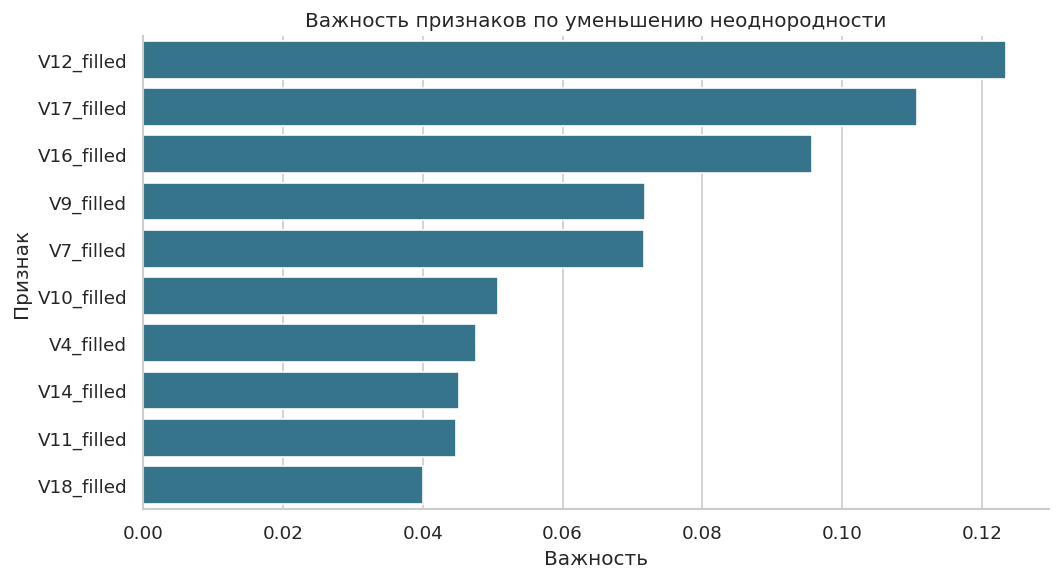

In [11]:
winner_scores = test_scores[winner]
group_stats = (winner_scores.assign(positive=lambda d: (d['score'] > thresholds[winner]).astype(int))
               .groupby('group_id').agg(score=('score', 'first'), positives=('Class', 'sum'), size=('Class', 'size')))
assert winner_scores.groupby('group_id')['score'].nunique().max() == 1
group_stats['negatives'] = group_stats['size'] - group_stats['positives']
group_stats['stratum'] = (group_stats['positives'] > 0).astype(int)
group_stats = group_stats.sort_values('score', ascending=False)
score_values = group_stats['score'].to_numpy()
score_ends = np.r_[np.flatnonzero(np.diff(score_values) != 0), len(score_values) - 1]
pos = group_stats['positives'].to_numpy(dtype=float)
neg = group_stats['negatives'].to_numpy(dtype=float)
pred = score_values > thresholds[winner]
strata = [np.flatnonzero(group_stats['stratum'].to_numpy() == value) for value in [0, 1]]
rng = np.random.default_rng(SEED)
bootstrap_rows = []
for _ in range(1000 if PROFILE == 'full' else 30):
    weights = np.zeros(len(group_stats), dtype=int)
    for indexes in strata:
        sampled = rng.choice(indexes, size=len(indexes), replace=True)
        weights += np.bincount(sampled, minlength=len(weights))
    wp, wn = weights * pos, weights * neg
    cumulative_tp = np.cumsum(wp)[score_ends]
    cumulative_total = np.cumsum(wp + wn)[score_ends]
    precision_curve = np.divide(cumulative_tp, cumulative_total, out=np.zeros_like(cumulative_tp), where=cumulative_total > 0)
    ap = float(np.sum(np.diff(np.r_[0, cumulative_tp]) / wp.sum() * precision_curve))
    tp, fp, fn = float(wp[pred].sum()), float(wn[pred].sum()), float(wp[~pred].sum())
    bootstrap_rows.append({'average_precision': ap, 'precision': tp / (tp + fp) if tp + fp else 0,
                           'recall': tp / (tp + fn), 'f1': 2 * tp / (2 * tp + fp + fn)})
bootstrap = pd.DataFrame(bootstrap_rows)
point_estimates = {**ranking_metrics(winner_scores['Class'], winner_scores['score']),
                   **threshold_metrics(winner_scores['Class'], winner_scores['score'], thresholds[winner])}
intervals = pd.DataFrame([{'metric': metric, 'estimate': point_estimates[metric],
                          'lower_95': bootstrap[metric].quantile(0.025), 'upper_95': bootstrap[metric].quantile(0.975)}
                         for metric in bootstrap.columns])
table('winner_confidence_intervals', intervals)
errors = winner_scores.assign(prediction=(winner_scores['score'] > thresholds[winner]).astype(int))
errors['outcome'] = np.select([(errors.Class == 1) & (errors.prediction == 1), (errors.Class == 0) & (errors.prediction == 1),
                              (errors.Class == 1) & (errors.prediction == 0)], ['TP', 'FP', 'FN'], default='TN')
error_summary = errors.groupby('outcome').agg(transactions=('Class', 'size'), median_amount=('Amount', 'median'),
                                            total_amount=('Amount', 'sum'), mean_score=('score', 'mean')).reset_index()
table('error_analysis', error_summary)
fraud_amount = errors.loc[errors.Class == 1, 'Amount'].sum()
captured_amount = errors.loc[errors.outcome == 'TP', 'Amount'].sum()
display(Markdown(f'Доля суммы мошеннических операций, попавших в обнаруженные: **{captured_amount / fraud_amount:.2%}**. '
                 'Это описательная метрика; сумма операции не равна доказанному предотвращённому ущербу.'))
classifier = models[winner].stages[-1]
importance = (classifier.coefficients if winner == 'lr' else classifier.featureImportances).toArray()
importance_table = pd.DataFrame({'feature': MODEL_FEATURES, 'value': importance}).assign(magnitude=np.abs(importance)).sort_values('magnitude', ascending=False)
table('winner_feature_importance', importance_table)
plt.figure(figsize=(9, 5))
sns.barplot(data=importance_table.head(10), y='feature', x='value', color='#267A9A')
plt.title('Коэффициенты стандартизированных признаков' if winner == 'lr' else 'Важность признаков по уменьшению неоднородности')
plt.xlabel('Коэффициент' if winner == 'lr' else 'Важность')
plt.ylabel('Признак')
figure('winner_importance')


## 10. Сохранение Pipeline и независимая загрузка

Сохраняется именно модель, оценённая на test, включая обработку признаков и рабочий порог.
После настройки порога она не дообучается на validation. Вход скоринга не требует ни `Class`,
ни обучающих весов. Проверка выполняется в новом Python-процессе с новой SparkSession.


In [12]:
model_path = OUT / 'models' / 'best_pipeline'
models[winner].write().overwrite().save(str(model_path))
loaded = PipelineModel.load(str(model_path))
without_label = test.drop('Class')
before = models[winner].transform(without_label).select('group_id', 'prediction', vector_to_array('probability')[1].alias('score'))
after = loaded.transform(without_label).select('group_id', 'prediction', vector_to_array('probability')[1].alias('score'))
left = before.groupBy('group_id', 'prediction', 'score').count()
right = after.groupBy('group_id', 'prediction', 'score').count()
assert left.exceptAll(right).count() == 0 and right.exceptAll(left).count() == 0
without_label.select('group_id', *RAW_FEATURES).write.mode('overwrite').parquet(str(OUT / 'reload_input'))
before.write.mode('overwrite').parquet(str(OUT / 'reload_expected'))
manifest = {'source': source_info, 'profile': PROFILE, 'model': winner, 'threshold': thresholds[winner],
            'parameters': best_parameters[winner], 'seed': SEED, 'features': MODEL_FEATURES,
            'required_input': NUMERIC, 'optional_input': ['Time'], 'prediction_rule': 'score > threshold',
            'training_rows': split_rows[0]['rows'], 'boundaries': {'train': cut_train, 'validation': cut_valid},
            'environment': environment, 'test_metrics': winner_row.to_dict(),
            'benchmark_metrics': benchmark_results.to_dict(orient='records'),
            'confidence_intervals': intervals.to_dict(orient='records'), 'trained_on_validation': False}
save_json('manifest.json', manifest)
for frame in split_frames.values():
    frame.unpersist()
spark.stop()
verification_env = dict(os.environ, PYSPARK_SUBMIT_ARGS='--driver-memory 1g pyspark-shell')
for key in ['PYSPARK_GATEWAY_PORT', 'PYSPARK_GATEWAY_SECRET']:
    verification_env.pop(key, None)
verification = subprocess.run([sys.executable, str(WORK.parent / 'verify_saved_model.py'), str(OUT)],
                              capture_output=True, text=True, timeout=600, env=verification_env)
print(verification.stdout)
if verification.returncode:
    print(verification.stderr[-12000:])
    raise RuntimeError('Независимая проверка сохранённого Pipeline завершилась ошибкой.')
reload_result = json.loads((OUT / 'reload_verification.json').read_text(encoding='utf-8'))
assert reload_result['passed']
display(reload_result)


{"passed": true, "rows": 56961, "max_score_difference": 0.0, "labels_and_multiplicity_equal": true, "inference_without_label_and_weights": true, "missing_value_inference": true, "minimal_input_inference": true, "independent_process": true}



{'passed': True,
 'rows': 56961,
 'max_score_difference': 0.0,
 'labels_and_multiplicity_equal': True,
 'inference_without_label_and_weights': True,
 'missing_value_inference': True,
 'minimal_input_inference': True,
 'independent_process': True}

## 11. Итоговые выводы

Следующий блок формирует выводы непосредственно из рассчитанных таблиц. Выбор модели сделан
на validation, а приведённые ниже показатели относятся к более позднему тестовому периоду.


In [13]:
selected = winner_row
baseline_accuracy = baseline['accuracy']
spark_bench = benchmark_results.set_index('framework').loc['spark']
sk_bench = benchmark_results.set_index('framework').loc['sklearn']
report = f"""
### Результат

По validation выбран **{winner.upper()}**, рабочий порог **{thresholds[winner]:.8f}**.
На независимом test: **AP {selected['average_precision']:.4f}**, **PR-AUC {selected['pr_auc_common']:.4f}**,
**ROC-AUC {selected['roc_auc']:.4f}**, **precision {selected['precision']:.3%}**,
**recall {selected['recall']:.3%}**, **F1 {selected['f1']:.4f}**.

Обнаружено **{int(selected['tp'])}** мошеннических операций, пропущено **{int(selected['fn'])}**.
Ложных тревог — **{int(selected['fp'])}**, или **{selected['false_alerts_per_10000']:.2f} на 10 000 операций**.
Постоянный прогноз легитимного класса даёт accuracy **{baseline_accuracy:.3%}**, но не обнаруживает
мошенничество. Поэтому accuracy не использовалась для выбора модели.

### Spark и sklearn

При одинаковых **{benchmark_n:,}** обучающих строках AP составила
**{spark_bench['average_precision']:.4f}** в Spark и **{sk_bench['average_precision']:.4f}** в sklearn.
Время обучения: **{spark_bench['fit_seconds']:.2f} с** и **{sk_bench['fit_seconds']:.2f} с** соответственно;
медиана трёх материализованных замеров скоринга:
**{spark_bench['median_scoring_seconds']:.3f} с** и **{sk_bench['median_scoring_seconds']:.3f} с**.
Преобразование в pandas учтено отдельно. sklearn работает с массивом в памяти одного процесса;
Spark управляет партициями, планом вычислений и заданиями, что создаёт накладные расходы в небольшом
локальном эксперименте, но позволяет переносить DataFrame/Pipeline-подход на более крупные данные.

### Сохранение и ограничения

Pipeline загружен в отдельном процессе: проверено **{reload_result['rows']}** предсказаний,
максимальное различие оценок **{reload_result['max_score_difference']:.3g}**.
Прогноз без метки и весов работает; кратность повторяющихся транзакций сохранена.

Выводы ограничены коротким периодом наблюдений и малым числом мошеннических операций.
Нет идентификаторов карт, поэтому невозможно исключить присутствие одной карты в разных периодах.
Исходное обучение PCA недоступно для аудита. Bootstrap-интервалы не покрывают всю неопределённость
временного дрейфа. Оценки риска не проходили отдельную калибровку вероятностей.
Важности PCA-компонент не дают причинного объяснения, а суммы операций не определяют стоимость ошибок.
Перед применением в банке потребуются более длинная временная проверка, заданные издержки ошибок,
проверка доступности признаков в момент операции и мониторинг изменений распределения данных.
"""
if PROFILE == 'smoke':
    report = '**Технический прогон: результаты не предназначены для сдачи.**\n\n' + report
display(Markdown(report))
(OUT / 'conclusions.md').write_text(report, encoding='utf-8')
save_json('completion.json', {'profile': PROFILE, 'completed_utc': datetime.now(timezone.utc).isoformat(),
                             'reload_verified': True, 'winner': winner, 'test_was_used_for_selection': False})



### Результат

По validation выбран **RF**, рабочий порог **0.35026400**.
На независимом test: **AP 0.7962**, **PR-AUC 0.7959**,
**ROC-AUC 0.9785**, **precision 87.097%**,
**recall 72.000%**, **F1 0.7883**.

Обнаружено **54** мошеннических операций, пропущено **21**.
Ложных тревог — **8**, или **1.40 на 10 000 операций**.
Постоянный прогноз легитимного класса даёт accuracy **99.868%**, но не обнаруживает
мошенничество. Поэтому accuracy не использовалась для выбора модели.

### Spark и sklearn

При одинаковых **100,000** обучающих строках AP составила
**0.7997** в Spark и **0.7997** в sklearn.
Время обучения: **4.48 с** и **1.94 с** соответственно;
медиана трёх материализованных замеров скоринга:
**0.328 с** и **0.020 с**.
Преобразование в pandas учтено отдельно. sklearn работает с массивом в памяти одного процесса;
Spark управляет партициями, планом вычислений и заданиями, что создаёт накладные расходы в небольшом
локальном эксперименте, но позволяет переносить DataFrame/Pipeline-подход на более крупные данные.

### Сохранение и ограничения

Pipeline загружен в отдельном процессе: проверено **56961** предсказаний,
максимальное различие оценок **0**.
Прогноз без метки и весов работает; кратность повторяющихся транзакций сохранена.

Выводы ограничены коротким периодом наблюдений и малым числом мошеннических операций.
Нет идентификаторов карт, поэтому невозможно исключить присутствие одной карты в разных периодах.
Исходное обучение PCA недоступно для аудита. Bootstrap-интервалы не покрывают всю неопределённость
временного дрейфа. Оценки риска не проходили отдельную калибровку вероятностей.
Важности PCA-компонент не дают причинного объяснения, а суммы операций не определяют стоимость ошибок.
Перед применением в банке потребуются более длинная временная проверка, заданные издержки ошибок,
проверка доступности признаков в момент операции и мониторинг изменений распределения данных.


## Воспроизведение и соответствие заданию

Разделы 1–3 закрывают загрузку, проверку, EDA и разделение данных; разделы 4–6 — Pipeline,
обучение, CrossValidator и сравнение моделей; разделы 7–9 — sklearn, метрики и оценку результатов;
раздел 10 — сохранение и повторную загрузку.

Полный запуск из папки проекта: `docker compose up -d`, затем выполнение ноутбука через
Jupyter по адресу `http://127.0.0.1:8888/?token=pyspark_ml` или запуск `run.ps1`.
После сохранения ноутбука и HTML необходимо выполнить `docker compose down`.
Автоматический скрипт делает это в блоке `finally`.

### Источники

- [Credit Card Fraud Detection — MLG-ULB](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- [Spark ML: настройка моделей](https://spark.apache.org/docs/3.5.3/ml-tuning.html)
- [Spark ML: Pipeline](https://spark.apache.org/docs/3.5.3/ml-pipeline.html)
- [sklearn: average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [sklearn: логистическая регрессия](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)


## Разбор результатов завершённого эксперимента

Random Forest выбран по validation PR-AUC: **0,7665** против **0,7153** у LR и **0,6191** у GBT. На test его AP составляет **0,7962**, а 95%-интервал группового bootstrap — **[0,7108; 0,8699]**. Интервал F1 — **[0,7111; 0,8572]**; при 75 мошеннических операциях в тесте оценка остаётся заметно неопределённой.

**Настройка порога не гарантирует улучшения в следующем периоде.** Для RF порог **0,350264**, выбранный на validation, дал на test F1 **0,7883**, тогда как стандартный порог **0,5** дал **0,8217**. Более низкий порог обнаружил одну дополнительную мошенническую операцию (54 вместо 53), но добавил семь ложных тревог (8 вместо 1). Это фактический компромисс на test, а не основание перенастраивать модель по нему. Сохранён Pipeline с заранее зафиксированным порогом; проверка его устойчивости требует новых временных периодов.

В отдельном контролируемом эксперименте логистическая регрессия на 100 000 строках получила AP около **0,7997** в обеих библиотеках и одинаковую матрицу ошибок. Это близко к AP выбранного RF, но данный эксперимент использует другие параметры и объём обучения. Его результат на test не используется для замены выбранного семейства и не доказывает превосходство меньшего объёма данных. Он показывает близость реализаций Spark и sklearn при согласованной постановке.

В этом локальном замере sklearn обучился за **1,94 с**, Spark — за **4,48 с**; медианное время скоринга составило **0,020 с** и **0,328 с** соответственно. Это измерение на одном компьютере и ограниченной подвыборке; вывод о скорости на распределённом кластере из него не следует.
